# Walkthrough

The same steps as `python -m spl_predictor`, one at a time.

**Question.** Before a Saudi Pro League match, can we tell whether it ends in a home win, a draw or an away win, better than always guessing "home win"?

In [1]:
import pandas as pd

from spl_predictor import plots
from spl_predictor.data import load_matches
from spl_predictor.evaluate import summarise, walk_forward
from spl_predictor.features import add_gap
from spl_predictor.models import candidates
from spl_predictor.pipeline import BACKTEST, TEST, next_week
from spl_predictor.predict import most_likely_winners, predict_week

pd.set_option("display.float_format", "{:.2f}".format)

## 1. Data: every league match since 2014-15

In [2]:
matches = load_matches()
played = matches.dropna(subset=["result"])
print(f"{len(played):,} played matches")
played["result"].value_counts(normalize=True)

2,940 played matches


result
H   0.44
A   0.33
D   0.23
Name: proportion, dtype: float64

Home wins are the most common result, draws the least. Always guessing "home win" is the baseline to beat.

## 2. One feature: the gap

Home team's goal difference per game over its last 50 league matches, minus the away team's. Only earlier matches count.

In [3]:
data = add_gap(matches)
data[["date", "home", "away", "home_form", "away_form", "gap", "result"]].tail(14).head(5)

,date,home,away,home_form,away_form,gap,result
2956,2027-05-24,Al-Kholood,Al-Fateh,-0.64,-0.50,-0.14,NaN
2957,2027-05-24,Al-Nassr,Al-Fayha,1.76,-0.48,2.24,NaN
2958,2027-05-24,Al-Qadsiah,Al-Hazem,1.38,-0.52,1.90,NaN
2959,2027-05-24,Diriyah Club,Al-Khaleej,-0.18,-0.38,0.20,NaN
2960,2027-05-24,Neom,Al-Shabab,0.04,-0.20,0.24,NaN


## 3. Backtest: train on earlier seasons, test the next, nine times

In [4]:
backtest, train_scores = walk_forward(data, candidates(), BACKTEST)
summary = summarise(backtest, train_scores)
summary[["matches", "accuracy", "log_loss", "train_log_loss", "gap"]]

,matches,accuracy,log_loss,train_log_loss,gap
model,,,,,
Always home win,2176.00,0.44,1.07,1.07,-0.01
Logistic regression,2176.00,0.53,0.99,0.98,0.01
Random forest,2176.00,0.45,3.73,0.49,3.24
Gradient boosting,2176.00,0.48,1.07,0.75,0.33


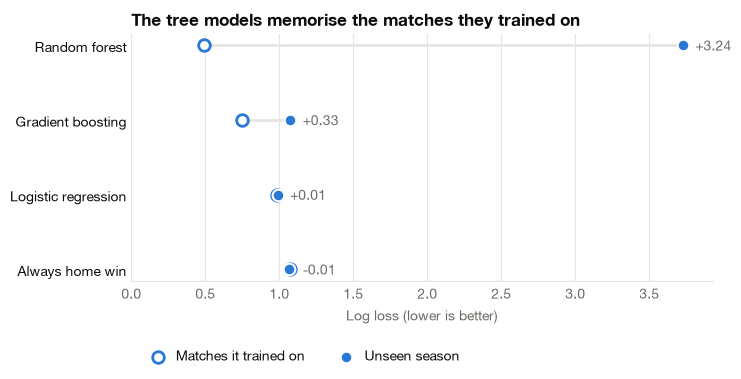

In [5]:
plots.overfitting_gap(summary);

## 4. The current season: never looked at while building

In [6]:
test, test_train = walk_forward(data, candidates(), [TEST])
summarise(test, test_train)[["matches", "accuracy", "log_loss"]]

,matches,accuracy,log_loss
model,,,
Always home win,94.00,0.39,1.09
Logistic regression,94.00,0.54,0.92
Random forest,94.00,0.45,2.56
Gradient boosting,94.00,0.49,0.96


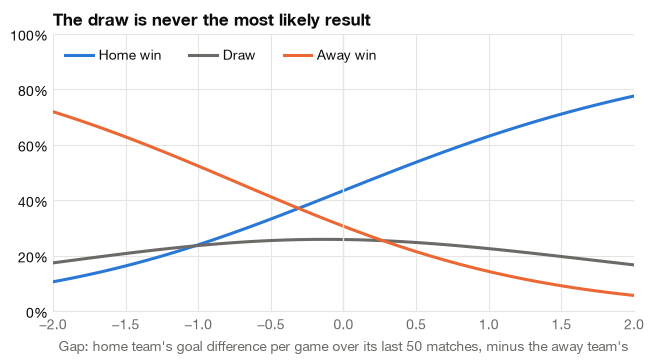

In [7]:
plots.probability_curve(candidates()["Logistic regression"], data[data["season"] < TEST]);

The draw curve never rises above the other two, so the model never picks a draw. Draws are about a quarter of all matches.

## 5. Next matchweek

In [8]:
season, week = next_week(data)
picks = predict_week(candidates()["Logistic regression"], data, season, week)
print(season, "matchweek", week)
picks[["date", "home", "away", "gap", "p_H", "p_D", "p_A", "pick"]]

2026-27 matchweek 12


,date,home,away,gap,p_H,p_D,p_A,pick
0,2026-10-29,Al-Khaleej,Al-Hazem,0.14,0.46,0.26,0.28,home win
1,2026-10-29,Al-Nassr,Al-Kholood,2.40,0.82,0.15,0.04,home win
2,2026-10-29,Al-Riyadh,Al-Qadsiah,-2.20,0.09,0.16,0.76,away win
3,2026-10-30,Abha,Al-Ittihad,-1.90,0.11,0.18,0.71,away win
4,2026-10-30,Al-Shabab,Al-Ahli,-1.46,0.17,0.21,0.63,away win
5,2026-10-30,Diriyah Club,Neom,-0.23,0.39,0.26,0.35,home win
6,2026-10-31,Al-Fayha,Al-Faisaly,0.00,0.43,0.26,0.31,home win
7,2026-10-31,Al-Hilal,Al-Fateh,2.26,0.80,0.15,0.04,home win
8,2026-10-31,Al-Taawoun,Al-Ettifaq,-0.08,0.42,0.26,0.32,home win


In [9]:
most_likely_winners(picks).head(5)

,club,opponent,win_chance
0,Al-Nassr,Al-Kholood,0.82
1,Al-Hilal,Al-Fateh,0.80
2,Al-Qadsiah,Al-Riyadh,0.76
3,Al-Ittihad,Abha,0.71
4,Al-Ahli,Al-Shabab,0.63
